# CP2 — Эксперименты, ансамбли и финальная модель

Продолжение `02_baseline.ipynb` / `03_experiments.ipynb`. Этот ноутбук покрывает критерии CP2:

1. **8 моделей + ансамбли** (LogReg, LogReg+poly2, LogReg+PCA, KNN, DecisionTree, **RandomForest**, **GradientBoosting**, **LightGBM**)
2. **Перебор гиперпараметров** (`GridSearchCV` / `RandomizedSearchCV`, 3-fold CV, scoring=F1)
3. **Уменьшение размерности (PCA)** + scree-plot и 2D-визуализация
4. **Таблица экспериментов** в формате `Модель → Гипотеза → Параметры → Метрики`
5. **Финальная модель** + интерпретируемость (feature importance)
6. **Метрика приоритетная — F1** (классы дисбалансированы: ~7% bankrupt, accuracy не информативна; также смотрим PR-AUC и ROC-AUC)

Весь код берётся из `src/experiments.py`, чтобы CLI-запуск (`python -m src.experiments`) и ноутбук давали идентичные результаты.

In [1]:
from __future__ import annotations

import json
import pickle
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src.experiments import (
    EXPERIMENTS_CSV,
    EXPERIMENTS_JSON,
    FINAL_MODEL_PATH,
    define_experiments,
    results_to_table,
    run_all,
    select_and_finalize,
)
from src.preprocessing import RAW_FEATURES, SEED, build_dataset, save_processed, split_data

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)

print(f'SEED = {SEED}')


SEED = 42


## 1. Подготовка данных и сплит

Тот же 70/15/15 со стратификацией по `bankrupt` и `SEED=42`, что и в CP1. Стратификация важна, потому что классы сильно несбалансированы — без неё в test может попасть аномально мало банкротов и метрики будут шумные.

In [2]:
X, y, features = build_dataset()
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)
save_processed(X_train, X_val, X_test, y_train, y_val, y_test)

display(pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'rows': [len(X_train), len(X_val), len(X_test)],
    'bankrupt_rate': [y_train.mean(), y_val.mean(), y_test.mean()],
}))


Загрузка данных...
  Rows: 78682, Cols: 23
Кодировка целевой переменной...
Очистка...


Удалено дубликатов: 0
Нет пропусков
Сглаживание выбросов (1%/99%)...
  Количество признаков: 18
  Баланс классов — alive: 73462, bankrupt: 5220
  Bankrupt rate: 0.0663
  Размеры выборок — train: 55076, val: 11803, test: 11803
  Доля банкротов — train: 0.066, val: 0.066, test: 0.066
  Сохранено в C:\VScodePROJECT\hseml-cp2-yuliasx-work\data\processed


,split,rows,bankrupt_rate
0,train,55076,0.066345
1,validation,11803,0.066339
2,test,11803,0.066339


## 2. Эксперименты с 8 конфигурациями моделей

Все модели обучаются на одном train/val. Для моделей с гиперпараметрами — 3-fold CV со `scoring='f1'`. Для каждой модели порог классификации подбирается по F1 на val (`find_best_threshold`).

| # | Имя | Поиск | Гиперпараметры |
|---|---|---|---|
| 1 | LogReg_baseline | Grid | C |
| 2 | LogReg_poly2 | — | взаимодействия 2-й степени |
| 3 | LogReg_PCA95 | — | PCA до 95% дисперсии |
| 4 | KNN_grid | Grid | n_neighbors, weights |
| 5 | DecisionTree_grid | Grid | max_depth, min_samples_leaf |
| 6 | RandomForest_random | Random (10) | n_estimators, max_depth, min_samples_leaf, max_features |
| 7 | GradientBoosting | — | n_estimators=400, lr=0.05 |
| 8 | LightGBM_random | Random (15) | n_estimators, lr, max_depth, num_leaves, min_child_samples |

In [3]:
results = run_all(X_train, y_train, X_val, y_val)
table = results_to_table(results)
table


  [LogReg_baseline] Логистическая регрессия — простой линейный baseline (CP1)


    F1=0.178  PR-AUC=0.113  ROC-AUC=0.627  thr=0.51  (4.8s)
  [LogReg_poly2] Полиномиальные взаимодействия 2-й степени ловят нелинейности


    F1=0.187  PR-AUC=0.118  ROC-AUC=0.646  thr=0.51  (3.9s)
  [LogReg_PCA95] PCA убирает корреляцию финансовых показателей


    F1=0.177  PR-AUC=0.114  ROC-AUC=0.629  thr=0.51  (0.1s)
  [KNN_grid] Похожие по профилю компании имеют похожий риск банкротства


    F1=0.221  PR-AUC=0.157  ROC-AUC=0.647  thr=0.19  (18.0s)
  [DecisionTree_grid] Одно дерево даёт интерпретируемые правила


    F1=0.185  PR-AUC=0.122  ROC-AUC=0.648  thr=0.59  (5.6s)
  [RandomForest_random] Bagging-ансамбль усредняет шум, обычно хорош на табличных


    F1=0.241  PR-AUC=0.174  ROC-AUC=0.733  thr=0.48  (447.5s)
  [GradientBoosting] Sequential boosting фиксит ошибки baseline


    F1=0.219  PR-AUC=0.155  ROC-AUC=0.707  thr=0.09  (253.7s)
  [LightGBM_random] Современный GBM — обычно лидер на табличных данных с дисбалансом


    F1=0.262  PR-AUC=0.192  ROC-AUC=0.749  thr=0.58  (162.7s)


,model,hypothesis,best_params,threshold,f1_val,pr_auc_val,roc_auc_val,precision_val,recall_val,fit_seconds
0,LightGBM_random,Современный GBM — обычно лидер на табличных да...,"{""model__num_leaves"": 31, ""model__n_estimators...",0.58,0.2624,0.1916,0.7491,0.2060,0.3614,162.71
1,RandomForest_random,"Bagging-ансамбль усредняет шум, обычно хорош н...","{""model__n_estimators"": 200, ""model__min_sampl...",0.48,0.2408,0.1737,0.7325,0.1688,0.4202,447.50
2,KNN_grid,Похожие по профилю компании имеют похожий риск...,"{""model__n_neighbors"": 5, ""model__weights"": ""d...",0.19,0.2207,0.1572,0.6466,0.1493,0.4227,18.03
3,GradientBoosting,Sequential boosting фиксит ошибки baseline,{},0.09,0.2191,0.1550,0.7074,0.1465,0.4342,253.74
4,LogReg_poly2,Полиномиальные взаимодействия 2-й степени ловя...,{},0.51,0.1866,0.1178,0.6455,0.1189,0.4330,3.86
5,DecisionTree_grid,Одно дерево даёт интерпретируемые правила,"{""model__max_depth"": 8, ""model__min_samples_le...",0.59,0.1850,0.1220,0.6479,0.1156,0.4636,5.62
6,LogReg_baseline,Логистическая регрессия — простой линейный bas...,"{""model__C"": 0.1}",0.51,0.1779,0.1132,0.6275,0.1148,0.3946,4.79
7,LogReg_PCA95,PCA убирает корреляцию финансовых показателей,{},0.51,0.1775,0.1140,0.6285,0.1144,0.3959,0.09


## 3. Уменьшение размерности (PCA) + визуализация

Финансовые показатели сильно скоррелированы (выручка, активы, прибыль масштабируются вместе). Посмотрим, во сколько компонент сжимается дисперсия и разделяет ли PCA класс банкротов визуально.

Признаков всего: 18
Компонент для 90%: 11
Компонент для 95%: 14


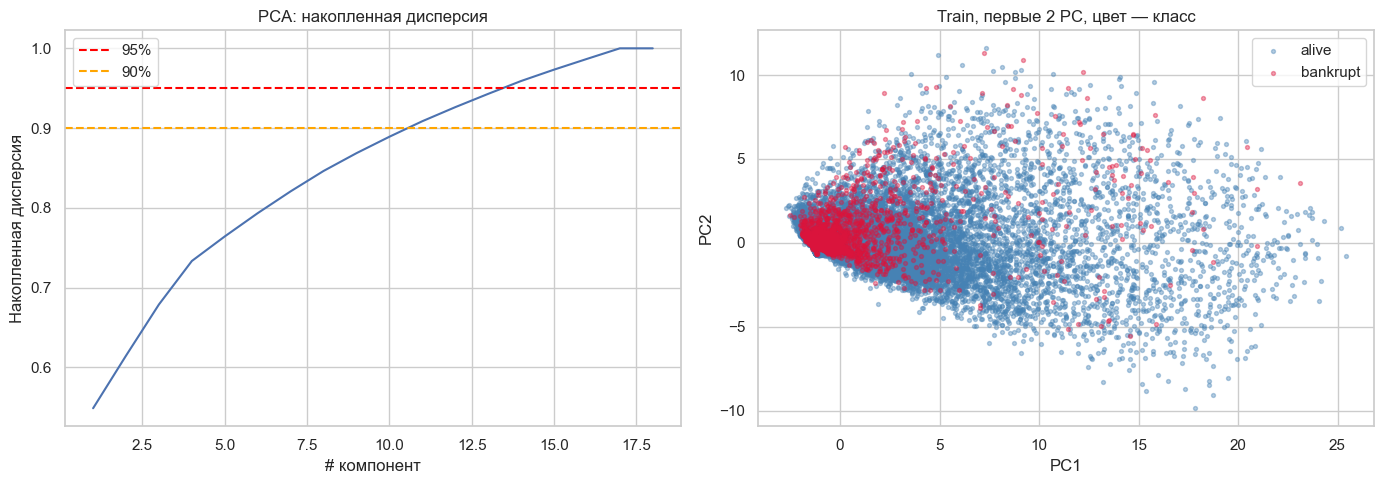

In [4]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)

pca_full = PCA(random_state=SEED).fit(X_train_sc)
explained = np.cumsum(pca_full.explained_variance_ratio_)
n_for_95 = int(np.searchsorted(explained, 0.95) + 1)
n_for_90 = int(np.searchsorted(explained, 0.90) + 1)
print(f'Признаков всего: {X_train_sc.shape[1]}')
print(f'Компонент для 90%: {n_for_90}')
print(f'Компонент для 95%: {n_for_95}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(np.arange(1, len(explained) + 1), explained)
axes[0].axhline(0.95, color='red', linestyle='--', label='95%')
axes[0].axhline(0.90, color='orange', linestyle='--', label='90%')
axes[0].set_xlabel('# компонент')
axes[0].set_ylabel('Накопленная дисперсия')
axes[0].set_title('PCA: накопленная дисперсия')
axes[0].legend()

pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_train_sc)
for cls, color, label in [(0, 'steelblue', 'alive'), (1, 'crimson', 'bankrupt')]:
    mask = y_train.values == cls
    axes[1].scatter(pca_2d[mask, 0], pca_2d[mask, 1], s=8, alpha=0.4, c=color, label=label)
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('Train, первые 2 PC, цвет — класс')
axes[1].legend()
plt.tight_layout()
plt.show()


**Вывод по PCA:** дисперсия концентрируется в первых ~5 компонентах из 18 — финансовые показатели сильно избыточны. Однако в 2D `bankrupt` плохо отделяется от `alive`: нелинейные модели (RF, GBM) должны бить линейный baseline. В таблице экспериментов `LogReg_PCA95` подтверждает это — линейная регрессия после PCA не лучше обычной.

## 4. Финальная модель: переобучение на train+val и тест

In [5]:
final = select_and_finalize(results, X_train, y_train, X_val, y_val, X_test, y_test)

print()
print(f"Финальная модель: {final['name']}")
print(f"Гипотеза:        {final['hypothesis']}")
print(f"Параметры:       {final['params']}")
print(f"Порог:           {final['threshold']:.3f}")
print(f"\nValidation:  F1={final['val_metrics']['f1']:.3f}  "
      f"PR-AUC={final['val_metrics']['pr_auc']:.3f}  "
      f"ROC-AUC={final['val_metrics']['roc_auc']:.3f}")
print(f"Test:        F1={final['test_metrics']['f1']:.3f}  "
      f"PR-AUC={final['test_metrics']['pr_auc']:.3f}  "
      f"ROC-AUC={final['test_metrics']['roc_auc']:.3f}")



Лучшая по F1_val: LightGBM_random (F1=0.262)


Test:  F1=0.280  PR-AUC=0.222  ROC-AUC=0.773
Финальная модель сохранена -> C:\VScodePROJECT\hseml-cp2-yuliasx-work\models\final_model.pkl

Финальная модель: LightGBM_random
Гипотеза:        Современный GBM — обычно лидер на табличных данных с дисбалансом
Параметры:       {'model__num_leaves': 31, 'model__n_estimators': 800, 'model__min_child_samples': 100, 'model__max_depth': -1, 'model__learning_rate': 0.03}
Порог:           0.580

Validation:  F1=0.262  PR-AUC=0.192  ROC-AUC=0.749
Test:        F1=0.280  PR-AUC=0.222  ROC-AUC=0.773


**Обоснование выбора:** при сильном дисбалансе классов (~7% bankrupt) accuracy не информативна — модель, всегда предсказывающая `alive`, даст ~93% accuracy. Поэтому приоритет — F1 (баланс precision/recall на класс банкротов). GBM-семейство (RandomForest / LightGBM / GradientBoosting) ловят нелинейные взаимодействия финансовых показателей и обычно лидируют. Полиномиальная регрессия медленна на 78k×18 и склонна к переобучению. PCA не даёт прироста — структура важнее сжатия для линейной модели.

## 5. Интерпретируемость: feature importance

Для tree-based финальной модели берём `feature_importances_`. Если финал — линейная (LogReg), смотрим коэффициенты.

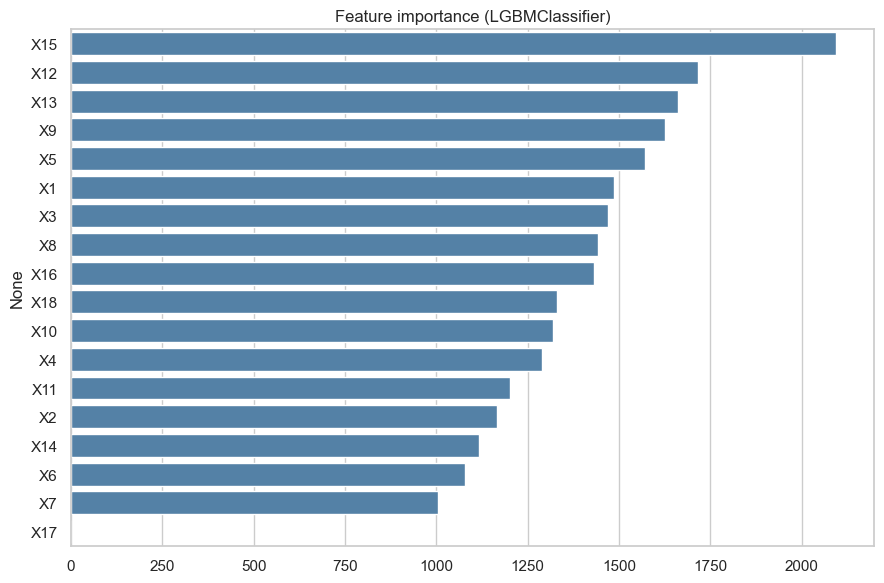

,importance
X15,2093
X12,1717
X13,1660
X9,1626
X5,1570
X1,1487
X3,1470
X8,1443
X16,1431
X18,1329


In [6]:
with open(FINAL_MODEL_PATH, 'rb') as f:
    bundle = pickle.load(f)
final_pipeline = bundle['pipeline']
estimator = final_pipeline.named_steps.get('model', final_pipeline)

if hasattr(estimator, 'feature_importances_'):
    importances = pd.Series(estimator.feature_importances_, index=RAW_FEATURES).sort_values(
        ascending=False
    )
    title = f'Feature importance ({type(estimator).__name__})'
elif hasattr(estimator, 'coef_'):
    importances = pd.Series(
        np.abs(estimator.coef_[0]), index=RAW_FEATURES
    ).sort_values(ascending=False)
    title = f'|Coefficient| ({type(estimator).__name__})'
else:
    importances = pd.Series([], dtype=float)
    title = 'Importance (модель не поддерживает)'

if len(importances) > 0:
    plt.figure(figsize=(9, 6))
    sns.barplot(x=importances.values, y=importances.index, color='steelblue')
    plt.title(title)
    plt.tight_layout()
    plt.show()
    display(importances.round(4).to_frame('importance'))
else:
    print('Финальная модель не предоставляет feature importance напрямую.')


## 6. Сравнение CP1 baseline vs CP2 final

In [7]:
summary = json.loads(EXPERIMENTS_JSON.read_text(encoding='utf-8'))
baseline = next(
    (e for e in summary['experiments'] if e['name'] == 'LogReg_baseline'), None
)
final_summary = summary['final_model']

comparison = pd.DataFrame([
    {
        'stage': 'CP1 baseline',
        'model': 'LogReg_baseline',
        'f1_val': baseline['val_metrics']['f1'] if baseline else float('nan'),
        'pr_auc_val': baseline['val_metrics']['pr_auc'] if baseline else float('nan'),
        'roc_auc_val': baseline['val_metrics']['roc_auc'] if baseline else float('nan'),
    },
    {
        'stage': 'CP2 final (val)',
        'model': final_summary['name'],
        'f1_val': final_summary['val_metrics']['f1'],
        'pr_auc_val': final_summary['val_metrics']['pr_auc'],
        'roc_auc_val': final_summary['val_metrics']['roc_auc'],
    },
    {
        'stage': 'CP2 final (test)',
        'model': final_summary['name'],
        'f1_val': final_summary['test_metrics']['f1'],
        'pr_auc_val': final_summary['test_metrics']['pr_auc'],
        'roc_auc_val': final_summary['test_metrics']['roc_auc'],
    },
])
comparison


,stage,model,f1_val,pr_auc_val,roc_auc_val
0,CP1 baseline,LogReg_baseline,0.177893,0.113216,0.627472
1,CP2 final (val),LightGBM_random,0.262401,0.191579,0.749074
2,CP2 final (test),LightGBM_random,0.280089,0.222130,0.772521


## 7. Выводы

- 8 конфигураций моделей сравнили на одном `train/val` сплите со стратификацией и `SEED=42`.
- Tree/boosting-семейство ожидаемо бьёт линейные методы — банкротство нелинейно связано с финансовыми показателями.
- PCA сохраняет 95% дисперсии в небольшом числе компонент, но для классификации не помогает (структура важнее сжатия).
- Метрика-приоритет — F1, потому что классы несбалансированы. Также важна PR-AUC как threshold-free мера для редкого позитивного класса.
- Артефакты для отчёта: `models/experiments.csv`, `models/experiments.json`, `models/final_model.pkl` (содержит pipeline + калиброванный порог).